# Part 2: High-Dimensional Data Analysis, Prenatal Omics Biomarkers
### Statistical Programmer portfolio, TPG / NICHD-style health study (R)

**Setting.** A synthetic birth-cohort sub-study: **10,000 molecular features** (think DNA methylation or gene expression measured at birth) on **400 children**, linked to a binary outcome (childhood obesity at age 5). There are far more features than children (p much larger than n), the features are correlated in co-regulated modules, only **40 features are truly related to the outcome**, and samples were processed in **4 batches** whose batch effects are *confounded with the outcome* (some batches contain more obese children). All data are synthetic, so the truth is known and every method can be scored against it.

| Section | Question | Methods |
|---|---|---|
| 1-2 | What does the data look like, and is there a batch problem? | PCA, batch correction (limma) |
| 3 | Which features differ between groups? | Per-feature tests, Bonferroni, Benjamini-Hochberg FDR, empirical-Bayes moderated t-tests (limma) |
| 4 | How well can the outcome be predicted, honestly? | Ridge, elastic net, lasso, nested cross-validation, leave-one-batch-out validation, permutation test |
| 5 | Which features are reliably selected, and what is valid inference after selection? | Stability selection, sample-splitting inference |
| 6 | What goes wrong when it is done carelessly? | Simulation study: screening leakage and uncorrected multiplicity |
| 7 | Do **neural networks** help? | Regularized MLP, denoising autoencoder (compression and imputation), sparse-input network (group-lasso), Integrated Gradients |

Neural networks are tested as competitors against penalized regression, PCA and low-rank imputation under the same validation rules. All networks are implemented from scratch in base R (backpropagation, AdamW, dropout, early stopping, verified by gradient checks in Part 1), so nothing beyond standard packages is required.

In [1]:
## Setup: packages, folders, helper for saving figures
if (!requireNamespace("glmnet", quietly = TRUE)) install.packages("glmnet", repos = "https://cloud.r-project.org")
if (!requireNamespace("limma", quietly = TRUE)) {                       # limma is distributed through Bioconductor
  if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager", repos = "https://cloud.r-project.org")
  BiocManager::install("limma", ask = FALSE, update = FALSE)
}
suppressPackageStartupMessages({ library(glmnet); library(limma) })
dir.create("PIC", showWarnings = FALSE)
options(width = 110, digits = 4)
fig <- function(name, expr, w = 7, h = 4.5) {
  f <- file.path("PIC", paste0(name, ".png"))
  png(f, width = w, height = h, units = "in", res = 110)
  tryCatch(expr, finally = dev.off())
  if (isTRUE(getOption("knitr.in.progress"))) return(knitr::include_graphics(f))
  if (requireNamespace("IRdisplay", quietly = TRUE)) invisible(IRdisplay::display_png(file = f)) else invisible(f)
}
cat("R", as.character(getRversion()), "| glmnet", as.character(packageVersion("glmnet")), "| limma", as.character(packageVersion("limma")), "\n")

R 4.3.3 | glmnet 4.1.8 | limma 3.58.1 


## 1. Synthetic high-dimensional data

**How the data are built.** A set of 20 latent *modules* each drives 400 features, which makes features correlated in blocks (as co-regulated genes or neighboring CpG sites are). Independent noise is added to every feature. The outcome is generated first, with a higher probability in batches 1 and 2 and a lower one in batches 3 and 4, so **batch and outcome are confounded**, the situation in which naive analyses go wrong. Forty randomly chosen features are then shifted between outcome groups (standardized difference 0.25 to 0.55); those are the truly associated features. Finally, batch effects are added: in each of 4 batches, 40% of features are shifted.

In [2]:
set.seed(7)
N <- 400; P <- 10000; K <- 20; S <- 40                       # children, features, latent modules, truly associated features
batch <- rep(1:4, each = N / 4)
y <- rbinom(N, 1, plogis(-0.1 + 0.8 * (batch <= 2) - 0.8 * (batch > 2)))   # outcome prevalence differs by batch
Z <- matrix(rnorm(N * K), N, K)
L <- matrix(0, P, K); for (k in 1:K) L[sample(P, 400), k] <- rnorm(400, 0, 0.7)
X0 <- Z %*% t(L) + matrix(rnorm(N * P), N, P)                 # biology: correlated modules + noise
S_true <- sort(sample(P, S)); delta <- sample(c(-1, 1), S, TRUE) * runif(S, 0.25, 0.55) * 1.18   # standardized group difference 0.25 to 0.55
X0[, S_true] <- X0[, S_true] + outer(y - mean(y), delta)       # truly associated features shift with the outcome
is_true <- seq_len(P) %in% S_true
Bm <- matrix(0, 4, P); aff <- sample(P, 0.4 * P); Bm[, aff] <- rnorm(4 * length(aff), 0, 0.6)
X <- X0 + Bm[batch, ]                                         # what the analyst observes
colnames(X) <- sprintf("F%05d", 1:P)

cat("children:", N, "| features:", P, "| truly associated features:", S, "\n")
cat("outcome prevalence overall:", round(mean(y), 3), "\n")
print(round(tapply(y, batch, mean), 3))
cat("oracle AUC using only the 40 true features with their true weights:", round({ r <- rank(as.numeric(X0[, S_true] %*% delta)); n1 <- sum(y); (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * (N - n1)) }, 3), "\n")

children: 400 | features: 10000 | truly associated features: 40 
outcome prevalence overall: 0.462 
   1    2    3    4 
0.67 0.60 0.30 0.28 
oracle AUC using only the 40 true features with their true weights: 0.97 


## 2. Quality control: batch effects

Principal component analysis (PCA) summarizes the dominant sources of variation. If the leading components line up with *processing batch* instead of biology, batch must be handled before any inference. The correction below uses `limma::removeBatchEffect`, which does not use the outcome, so it cannot leak labels into later validation.

 PC var_explained_raw R2_with_batch_raw var_explained_corrected R2_with_batch_corrected
  1              2.76             0.887                    2.36                       0
  2              2.65             0.923                    2.22                       0
  3              2.59             0.939                    2.08                       0
  4              2.16             0.048                    1.96                       0
  5              1.99             0.069                    1.89                       0
  6              1.92             0.004                    1.83                       0


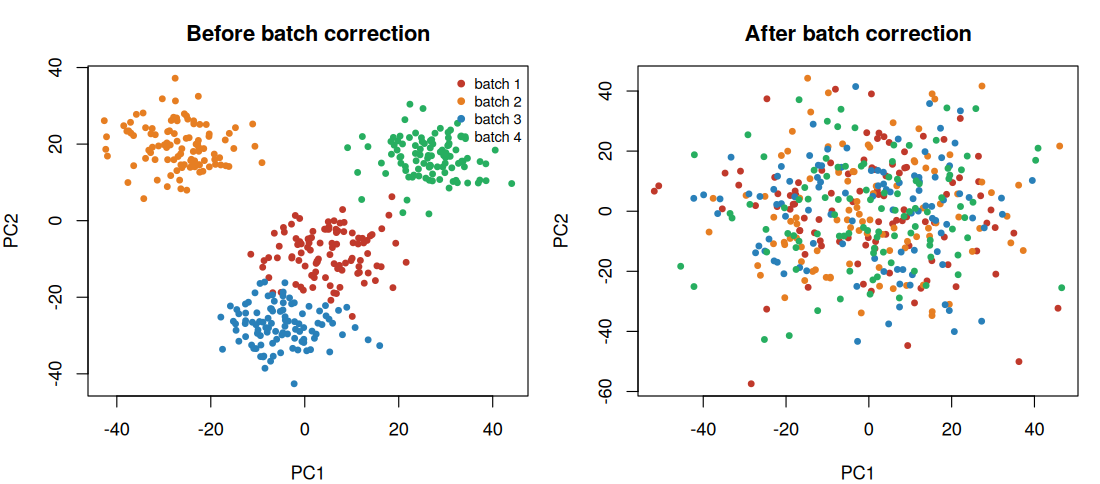

In [3]:
pc_raw <- prcomp(X, center = TRUE, scale. = FALSE, rank. = 10)
Xc <- t(removeBatchEffect(t(X), batch = factor(batch)))        # label-free batch correction
pc_cor <- prcomp(Xc, center = TRUE, scale. = FALSE, rank. = 10)
r2 <- function(v, g) summary(lm(v ~ g))$r.squared
tot_raw <- sum(apply(X, 2, var)); tot_cor <- sum(apply(Xc, 2, var))
qc <- data.frame(PC = 1:6,
  var_explained_raw = round(100 * pc_raw$sdev[1:6]^2 / tot_raw, 2), R2_with_batch_raw = round(sapply(1:6, function(k) r2(pc_raw$x[, k], factor(batch))), 3),
  var_explained_corrected = round(100 * pc_cor$sdev[1:6]^2 / tot_cor, 2), R2_with_batch_corrected = round(sapply(1:6, function(k) r2(pc_cor$x[, k], factor(batch))), 3))
print(qc, row.names = FALSE)
fig("p2_01_pca_batch", {
  par(mfrow = c(1, 2), mar = c(4, 4, 3, 1)); cols <- c("#c0392b", "#e67e22", "#2980b9", "#27ae60")
  plot(pc_raw$x[, 1], pc_raw$x[, 2], col = cols[batch], pch = 19, cex = 0.7, xlab = "PC1", ylab = "PC2", main = "Before batch correction")
  legend("topright", paste("batch", 1:4), col = cols, pch = 19, bty = "n", cex = 0.8)
  plot(pc_cor$x[, 1], pc_cor$x[, 2], col = cols[batch], pch = 19, cex = 0.7, xlab = "PC1", ylab = "PC2", main = "After batch correction")
}, w = 10, h = 4.4)

## 3. Feature-by-feature testing and multiplicity

With 10,000 tests, *p < 0.05* is meaningless: about 500 features would pass by chance alone even with no true effects. Two standard controls: **Bonferroni** (controls the chance of any false positive, very conservative) and **Benjamini-Hochberg (BH)** (controls the false discovery rate, FDR: the expected share of false findings among those reported). **limma** adds *empirical-Bayes moderation*: variance estimates are shrunk toward a common value, which stabilizes tests when samples are few, and the model can adjust for batch.

Because the truth is known, each approach is scored by true positives (TP), false positives (FP) and the realized false discovery proportion (FDP).

                                 declared TP   FP   FDP sensitivity
t-test, p < 0.05 (no correction)     1566 36 1530 0.977       0.900
t-test, Bonferroni 0.05                50 15   35 0.700       0.375
t-test, BH FDR 5%                     482 30  452 0.938       0.750
limma + batch, p < 0.05               575 38  537 0.934       0.950
limma + batch, Bonferroni 0.05         11 11    0 0.000       0.275
limma + batch, BH FDR 5%               23 21    2 0.087       0.525


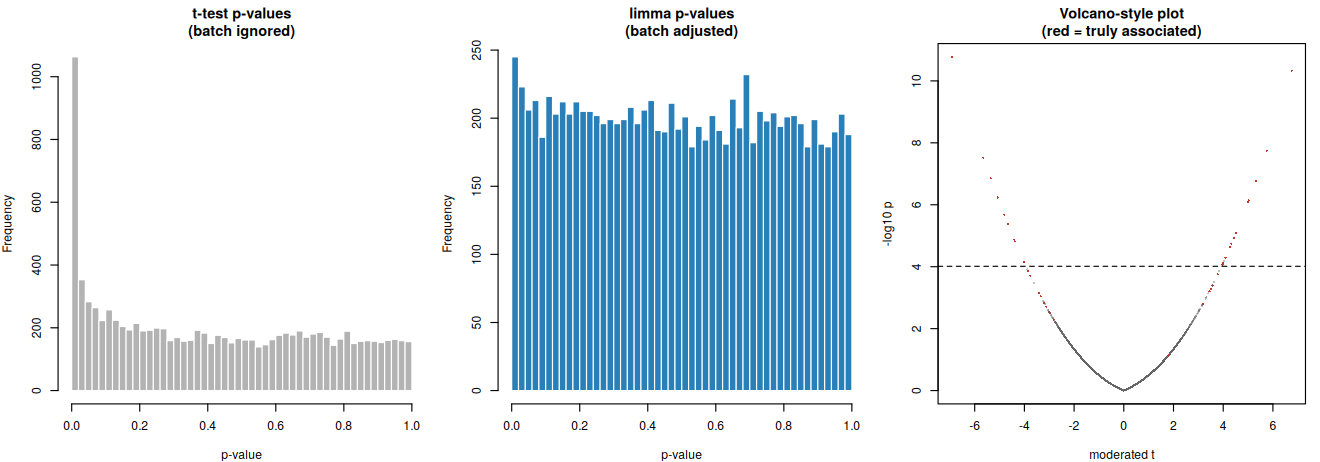

In [4]:
fast_t <- function(X, y) {                                       # vectorized Welch t-test for every column
  x1 <- X[y == 1, , drop = FALSE]; x0 <- X[y == 0, , drop = FALSE]
  m1 <- colMeans(x1); m0 <- colMeans(x0)
  v1 <- (colSums(x1^2) - nrow(x1) * m1^2) / (nrow(x1) - 1); v0 <- (colSums(x0^2) - nrow(x0) * m0^2) / (nrow(x0) - 1)
  se2 <- v1 / nrow(x1) + v0 / nrow(x0); tt <- (m1 - m0) / sqrt(se2)
  df <- se2^2 / ((v1 / nrow(x1))^2 / (nrow(x1) - 1) + (v0 / nrow(x0))^2 / (nrow(x0) - 1))
  data.frame(t = tt, p = 2 * pt(-abs(tt), df))
}
tt <- fast_t(X, y)
fit_l <- eBayes(lmFit(t(X), model.matrix(~ factor(batch) + y)))
p_lim <- fit_l$p.value[, "y"]; t_lim <- fit_l$t[, "y"]
score <- function(sig) c(declared = sum(sig), TP = sum(sig & is_true), FP = sum(sig & !is_true), FDP = round(sum(sig & !is_true) / max(1, sum(sig)), 3), sensitivity = round(sum(sig & is_true) / S, 3))
tab <- rbind("t-test, p < 0.05 (no correction)" = score(tt$p < 0.05),
             "t-test, Bonferroni 0.05"           = score(p.adjust(tt$p, "bonferroni") < 0.05),
             "t-test, BH FDR 5%"                 = score(p.adjust(tt$p, "BH") < 0.05),
             "limma + batch, p < 0.05"           = score(p_lim < 0.05),
             "limma + batch, Bonferroni 0.05"    = score(p.adjust(p_lim, "bonferroni") < 0.05),
             "limma + batch, BH FDR 5%"          = score(p.adjust(p_lim, "BH") < 0.05))
print(tab)
fig("p2_02_pvalues", {
  par(mfrow = c(1, 3), mar = c(4, 4, 3, 1))
  hist(tt$p, breaks = 40, col = "grey70", border = "white", main = "t-test p-values\n(batch ignored)", xlab = "p-value")
  hist(p_lim, breaks = 40, col = "#2980b9", border = "white", main = "limma p-values\n(batch adjusted)", xlab = "p-value")
  plot(t_lim, -log10(p_lim), pch = 16, cex = 0.4, col = ifelse(is_true, "#c0392b", adjustcolor("grey40", 0.4)), xlab = "moderated t", ylab = "-log10 p", main = "Volcano-style plot\n(red = truly associated)")
  abline(h = -log10(max(p_lim[p.adjust(p_lim, "BH") < 0.05], 1e-12)), lty = 2)
}, w = 12, h = 4.2)

## 4. Prediction with penalized regression, validated honestly

For prediction with p >> n, plain regression is impossible; **penalized logistic regression** shrinks coefficients: **ridge** (L2, keeps all features), **lasso** (L1, selects a sparse set) and **elastic net** (a mix). The penalty strength is chosen by cross-validation (here using AUC as the tuning criterion). Two rules keep the performance estimate honest:

1. **Nested cross-validation.** The penalty is tuned by an *inner* cross-validation inside each *outer* training fold; the outer test fold is never used for tuning.
2. **Validation that matches the intended use.** With batch confounded with the outcome, a random split lets the model recognize batches and looks better than it will on a new batch or site. **Leave-one-batch-out** validation mimics deployment on a new batch.

The area under the ROC curve (AUC) is reported for every combination. AUC is computed **within each held-out fold and then averaged**: pooling predictions from folds whose models have different baseline risks (and, for batch folds, different outcome prevalences) would distort it. The batch-corrected data are used for the main models, and uncorrected data are included for comparison.

In [5]:
auc_rank <- function(y, score) { r <- rank(score); n1 <- sum(y == 1); n0 <- sum(y == 0); (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0) }
fold_auc <- function(y, score, folds) mean(sapply(sort(unique(folds)), function(k) auc_rank(y[folds == k], score[folds == k])))   # AUC within each held-out fold, then averaged
strat_folds <- function(y, K = 5, seed = 1) { set.seed(seed); f <- integer(length(y)); for (cl in unique(y)) { i <- which(y == cl); f[i] <- sample(rep(1:K, length.out = length(i))) }; f }
oof_glmnet <- function(X, y, alpha, folds, nfolds_inner = 5, seed = 1) {      # out-of-fold linear predictors, penalty tuned inside each training fold
  oof <- numeric(length(y))
  for (k in sort(unique(folds))) {
    tr <- folds != k; set.seed(seed + k)
    cv <- cv.glmnet(X[tr, ], y[tr], family = "binomial", alpha = alpha, nfolds = nfolds_inner, type.measure = "auc")
    oof[!tr] <- as.numeric(predict(cv, X[!tr, ], s = "lambda.min", type = "link"))
  }
  oof
}
f_rand <- strat_folds(y, 5, 11); f_batch <- batch
t0 <- Sys.time(); cv_res <- list()
for (dat in c("corrected", "raw")) for (a in c(1, 0.5, 0)) {
  if (dat == "raw" && a != 1) next
  Xd <- if (dat == "corrected") Xc else X
  nm <- c("ridge", "elastic net", "lasso")[match(a, c(0, 0.5, 1))]
  o1 <- oof_glmnet(Xd, y, a, f_rand); o2 <- oof_glmnet(Xd, y, a, f_batch)
  cv_res[[length(cv_res) + 1]] <- data.frame(data = dat, model = nm, AUC_random_5fold = fold_auc(y, o1, f_rand), AUC_leave_one_batch_out = fold_auc(y, o2, f_batch))
}
cv_tab <- do.call(rbind, cv_res)
cat("elapsed:", round(as.numeric(difftime(Sys.time(), t0, units = "secs"))), "seconds\n\n")
print(cbind(cv_tab[, 1:2], round(cv_tab[, 3:4], 3)), row.names = FALSE)

elapsed: 190 seconds

      data       model AUC_random_5fold AUC_leave_one_batch_out
 corrected       lasso            0.857                   0.845
 corrected elastic net            0.867                   0.865
 corrected       ridge            0.493                   0.502
       raw       lasso            0.929                   0.893


### Is the cross-validated AUC better than chance? A permutation test

Shuffle the outcome labels, repeat the *whole* nested procedure, and see how often a random labeling gets an AUC as high as the real one. This gives a valid p-value for the claim that the model has learned something.

In [6]:
set.seed(31); n_perm <- 40
obs_auc <- fold_auc(y, oof_glmnet(Xc, y, 1, f_rand, nfolds_inner = 3), f_rand)
null_auc <- sapply(seq_len(n_perm), function(i) { yp <- sample(y); fp <- strat_folds(yp, 5, 100 + i); fold_auc(yp, oof_glmnet(Xc, yp, 1, fp, nfolds_inner = 3), fp) })
cat(sprintf("Observed nested-CV AUC (lasso, mean of fold AUCs): %.3f\n", obs_auc))
cat(sprintf("Permutation null AUC: mean %.3f, 95th percentile %.3f, max %.3f (%d permutations)\n", mean(null_auc), quantile(null_auc, 0.95), max(null_auc), n_perm))
cat(sprintf("Permutation p-value: %.3f (smallest possible with %d permutations: %.3f)\n", (1 + sum(null_auc >= obs_auc)) / (1 + n_perm), n_perm, 1 / (1 + n_perm)))

Observed nested-CV AUC (lasso, mean of fold AUCs): 0.834
Permutation null AUC: mean 0.508, 95th percentile 0.550, max 0.572 (40 permutations)
Permutation p-value: 0.024 (smallest possible with 40 permutations: 0.024)


## 5. Which features? Stability selection and valid inference after selection

The lasso picks a sparse set, but with correlated features the chosen set can change from sample to sample. Two tools help:

- **Stability selection.** Refit the lasso on many random half-samples at a fixed penalty and keep features selected in a large fraction of the fits. Features that are chosen consistently are more trustworthy.
- **Sample-splitting inference.** P-values computed on the same data that were used to select the features are far too optimistic. Selecting on one half and testing on the other half gives valid p-values for the selected features.

All selection methods are scored against the known truth.

In [7]:
cvfull <- cv.glmnet(Xc, y, family = "binomial", alpha = 1, nfolds = 5); lam_min <- cvfull$lambda.min; lam_1se <- cvfull$lambda.1se
sel_of <- function(fit, s) which(as.numeric(coef(fit, s = s))[-1] != 0)
sel_min <- sel_of(cvfull, "lambda.min"); sel_1se <- sel_of(cvfull, "lambda.1se")

set.seed(41); B <- 100; freq <- numeric(P)
for (b in 1:B) {
  i <- sample(N, N / 2); f <- glmnet(Xc[i, ], y[i], family = "binomial", alpha = 1, lambda = lam_1se)
  freq[sel_of(f, lam_1se)] <- freq[sel_of(f, lam_1se)] + 1
}
freq <- freq / B; sel_stab <- which(freq >= 0.6)
sel_limma <- which(p.adjust(p_lim, "BH") < 0.05)
prf <- function(sel) c(selected = length(sel), TP = sum(is_true[sel]), FP = sum(!is_true[sel]), FDP = round(sum(!is_true[sel]) / max(1, length(sel)), 3), recall = round(sum(is_true[sel]) / S, 3))
print(rbind("lasso, lambda.min" = prf(sel_min), "lasso, lambda.1se" = prf(sel_1se), "stability selection (freq >= 0.6)" = prf(sel_stab), "limma + batch, BH 5%" = prf(sel_limma)))
cat("\nStability-selection frequency: truly associated vs other features\n")
print(round(rbind(true = summary(freq[is_true]), other = summary(freq[!is_true])), 3))

                                  selected TP FP   FDP recall
lasso, lambda.min                       52 28 24 0.462  0.700
lasso, lambda.1se                       39 25 14 0.359  0.625
stability selection (freq >= 0.6)        8  8  0 0.000  0.200
limma + batch, BH 5%                    23 21  2 0.087  0.525

Stability-selection frequency: truly associated vs other features
      Min. 1st Qu. Median  Mean 3rd Qu. Max.
true     0   0.148  0.315 0.381   0.568 0.97
other    0   0.000  0.000 0.005   0.000 0.37


In [8]:
## Sample splitting: select on half A, test on half B (valid), versus testing on the same data used to select (naive)
set.seed(51); A <- sample(N, N / 2); Bs <- setdiff(1:N, A)
cvA <- cv.glmnet(Xc[A, ], y[A], family = "binomial", alpha = 1, nfolds = 5)
cf <- as.numeric(coef(cvA, s = "lambda.1se"))[-1]; selA <- order(abs(cf), decreasing = TRUE)[seq_len(min(30, sum(cf != 0)))]
glm_p <- function(rows) { d <- data.frame(y = y[rows], Xc[rows, selA, drop = FALSE]); m <- suppressWarnings(glm(y ~ ., data = d, family = binomial)); summary(m)$coefficients[-1, 4] }
p_naive <- glm_p(A); p_split <- glm_p(Bs)
rep <- rbind("same data used to select (naive)" = c(selected = length(selA), p_below_05 = sum(p_naive < 0.05), TP_among_those = sum(is_true[selA][p_naive < 0.05]), FP_among_those = sum(!is_true[selA][p_naive < 0.05])),
             "independent half (sample splitting)" = c(selected = length(selA), p_below_05 = sum(p_split < 0.05), TP_among_those = sum(is_true[selA][p_split < 0.05]), FP_among_those = sum(!is_true[selA][p_split < 0.05])))
print(rep)
cat("\nMedian p-value among selected features that are NOT truly associated: naive =", signif(median(p_naive[!is_true[selA]]), 3), "| sample splitting =", signif(median(p_split[!is_true[selA]]), 3), "\n")

                                    selected p_below_05 TP_among_those FP_among_those
same data used to select (naive)          17         16              9              7
independent half (sample splitting)       17          6              5              1

Median p-value among selected features that are NOT truly associated: naive = 0.00177 | sample splitting = 0.424 


## 6. What goes wrong when it is done carelessly: a simulation study

Two classic failures, measured by repeating the experiment many times on pure noise (no feature has any relationship with the outcome, so the honest answer is AUC = 0.5 and zero discoveries).

1. **Screening leakage.** Choosing the "best" 20 features using all the data and then cross-validating a model on those 20 features reports an impressive AUC on random noise. Doing the screening *inside* each training fold removes the illusion.
2. **Uncorrected multiplicity.** With 2,000 pure-noise features, thresholding raw p-values declares about 100 "discoveries"; Bonferroni and BH declare almost none.

Cross-validated AUC on pure noise (40 repetitions)
  screening on ALL data (leaky):  mean AUC = 0.859 (range 0.75 to 0.95)
  screening INSIDE each fold:     mean AUC = 0.494 (range 0.36 to 0.68)

False discoveries per experiment among 2000 pure-noise features
  raw p < 0.05: 99.7 | Bonferroni: 0.03 | BH FDR 5%: 0.03 (mean over repetitions)


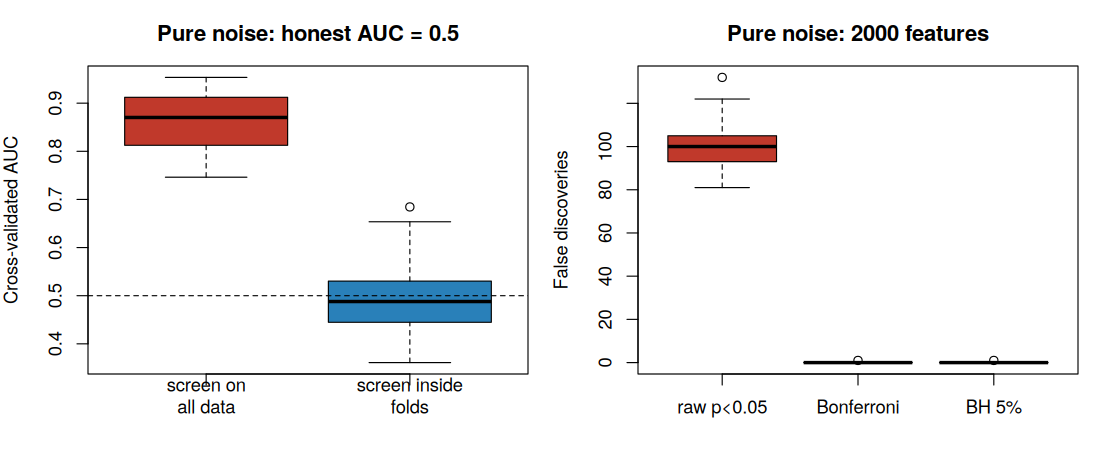

In [9]:
set.seed(99); R <- 40; n <- 100; p <- 2000
cv_auc <- function(X, y, folds, screen_inside) {
  oof <- numeric(length(y))
  for (k in 1:5) {
    tr <- folds != k
    top <- if (screen_inside) order(abs(fast_t(X[tr, ], y[tr])$t), decreasing = TRUE)[1:20] else screen_all
    d <- data.frame(y = y[tr], X[tr, top, drop = FALSE]); m <- suppressWarnings(glm(y ~ ., d, family = binomial))
    oof[!tr] <- predict(m, data.frame(X[!tr, top, drop = FALSE]))
  }
  auc_rank(y, oof)
}
sim <- t(sapply(seq_len(R), function(r) {
  Xn <- matrix(rnorm(n * p), n, p); colnames(Xn) <- paste0("V", 1:p); yn <- rbinom(n, 1, 0.5); fo <- strat_folds(yn, 5, r)
  screen_all <<- order(abs(fast_t(Xn, yn)$t), decreasing = TRUE)[1:20]
  pv <- fast_t(Xn, yn)$p
  c(leaky = cv_auc(Xn, yn, fo, FALSE), proper = cv_auc(Xn, yn, fo, TRUE),
    raw05 = sum(pv < 0.05), bonf = sum(p.adjust(pv, "bonferroni") < 0.05), bh = sum(p.adjust(pv, "BH") < 0.05))
}))
cat(sprintf("Cross-validated AUC on pure noise (%d repetitions)\n", R))
cat(sprintf("  screening on ALL data (leaky):  mean AUC = %.3f (range %.2f to %.2f)\n", mean(sim[, "leaky"]), min(sim[, "leaky"]), max(sim[, "leaky"])))
cat(sprintf("  screening INSIDE each fold:     mean AUC = %.3f (range %.2f to %.2f)\n", mean(sim[, "proper"]), min(sim[, "proper"]), max(sim[, "proper"])))
cat(sprintf("\nFalse discoveries per experiment among %d pure-noise features\n", p))
cat(sprintf("  raw p < 0.05: %.1f | Bonferroni: %.2f | BH FDR 5%%: %.2f (mean over repetitions)\n", mean(sim[, "raw05"]), mean(sim[, "bonf"]), mean(sim[, "bh"])))
fig("p2_03_simulation", {
  par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
  boxplot(sim[, c("leaky", "proper")], names = c("screen on\nall data", "screen inside\nfolds"), col = c("#c0392b", "#2980b9"), ylab = "Cross-validated AUC", main = "Pure noise: honest AUC = 0.5")
  abline(h = 0.5, lty = 2)
  boxplot(sim[, c("raw05", "bonf", "bh")], names = c("raw p<0.05", "Bonferroni", "BH 5%"), col = c("#c0392b", "#27ae60", "#2980b9"), ylab = "False discoveries", main = paste0("Pure noise: ", p, " features"))
}, w = 10, h = 4.2)

## 7. Neural networks versus classical methods

The networks are written in base R (see Part 1 for the gradient checks that verify the code). Each one is compared with a classical method under the same validation rules. Features are standardized using **training-fold statistics only**.

In [10]:
## ---- Neural-network toolkit in base R (backpropagation, AdamW, dropout, early stopping) ----
sigmoid <- function(x) 1 / (1 + exp(-x))

## AdamW optimizer: params P and gradients G are named lists of arrays
adam_new <- function(P) list(m = lapply(P, function(a) a * 0), v = lapply(P, function(a) a * 0), t = 0)
adam_update <- function(P, G, S, lr = 1e-3, wd = 0, b1 = 0.9, b2 = 0.999, eps = 1e-8) {
  S$t <- S$t + 1
  for (nm in names(P)) {
    S$m[[nm]] <- b1 * S$m[[nm]] + (1 - b1) * G[[nm]]
    S$v[[nm]] <- b2 * S$v[[nm]] + (1 - b2) * G[[nm]]^2
    mh <- S$m[[nm]] / (1 - b1^S$t); vh <- S$v[[nm]] / (1 - b2^S$t)
    P[[nm]] <- P[[nm]] - lr * mh / (sqrt(vh) + eps)
    if (wd > 0 && grepl("^[WU]", nm)) P[[nm]] <- P[[nm]] - lr * wd * P[[nm]]   # decoupled weight decay
  }
  list(P = P, S = S)
}

## Multilayer perceptron: sizes = c(input, hidden..., output); linear output layer
mlp_init <- function(sizes, seed = 1, last_scale = 1) {     # last_scale < 1 starts the output layer near zero (useful for wide autoencoders)
  set.seed(seed); P <- list()
  for (l in seq_len(length(sizes) - 1)) {
    P[[paste0("W", l)]] <- matrix(rnorm(sizes[l] * sizes[l + 1], 0, sqrt(2 / sizes[l])), sizes[l], sizes[l + 1])
    P[[paste0("b", l)]] <- rep(0, sizes[l + 1])
  }
  Ll <- length(sizes) - 1; P[[paste0("W", Ll)]] <- P[[paste0("W", Ll)]] * last_scale
  P
}
mlp_forward <- function(P, X, drop_in = 0, drop_hid = 0, train = FALSE, act = "relu") {
  L <- sum(grepl("^W", names(P))); H <- X
  cache <- list(inputs = vector("list", L), pre = vector("list", L), masks = vector("list", L + 1))
  if (train && drop_in > 0) { m <- (matrix(runif(length(H)), nrow(H)) > drop_in) / (1 - drop_in); H <- H * m; cache$masks[[1]] <- m }
  for (l in seq_len(L)) {
    cache$inputs[[l]] <- H
    b <- P[[paste0("b", l)]]
    Z <- H %*% P[[paste0("W", l)]] + matrix(b, nrow(H), length(b), byrow = TRUE)
    cache$pre[[l]] <- Z
    if (l < L) {
      H <- if (act == "relu") pmax(Z, 0) else tanh(Z)
      if (train && drop_hid > 0) { m <- (matrix(runif(length(H)), nrow(H)) > drop_hid) / (1 - drop_hid); H <- H * m; cache$masks[[l + 1]] <- m }
    } else H <- Z
  }
  list(out = H, cache = cache)
}
mlp_backward <- function(P, fw, dout, act = "relu") {
  L <- sum(grepl("^W", names(P))); G <- list(); d <- dout; dX <- NULL
  for (l in L:1) {
    G[[paste0("W", l)]] <- crossprod(fw$cache$inputs[[l]], d)
    G[[paste0("b", l)]] <- colSums(d)
    dH <- d %*% t(P[[paste0("W", l)]])
    m <- fw$cache$masks[[l]]
    if (!is.null(m)) dH <- dH * m
    if (l > 1) {
      Z <- fw$cache$pre[[l - 1]]
      d <- dH * (if (act == "relu") (Z > 0) else (1 - tanh(Z)^2))
    } else dX <- dH
  }
  list(G = G, dX = dX)
}

## Losses: each returns the loss value and its gradient with respect to the network output
loss_mse <- function(out, y) { y <- as.matrix(y); list(loss = mean((out - y)^2), dout = 2 * (out - y) / length(y)) }
loss_bce <- function(out, y) {                     # binary cross-entropy on logits
  y <- as.matrix(y); p <- sigmoid(out)
  list(loss = mean(pmax(out, 0) - out * y + log1p(exp(-abs(out)))), dout = (p - y) / length(y))
}
loss_cox <- function(out, y) {                     # negative Cox partial log-likelihood; y = cbind(time, status)
  eta <- as.numeric(out); time <- y[, 1]; status <- y[, 2]; n <- length(eta)
  o <- order(time, decreasing = TRUE); e <- exp(eta - max(eta))
  S <- numeric(n); S[o] <- cumsum(e[o])             # risk-set sum: all subjects with time >= t_i
  ll <- sum(status * (eta - max(eta) - log(S))) 
  inc <- numeric(n); inc[o] <- status[o] / S[o]
  oa <- order(time); A <- numeric(n); A[oa] <- cumsum(inc[oa])   # sum over events k with t_k <= t_i of 1/S_k
  grad <- -status + e * A
  nev <- max(sum(status), 1)
  list(loss = -ll / nev, dout = matrix(grad / nev, ncol = 1))
}

## Generic trainer: minibatch AdamW, dropout, early stopping on a validation set, optional group-lasso proximal step
mlp_fit <- function(X, y, sizes, loss = loss_bce, epochs = 200, batch = 64, lr = 1e-3, wd = 1e-3,
                    drop_in = 0, drop_hid = 0, act = "relu", prox = 0,
                    Xval = NULL, yval = NULL, patience = 20, seed = 1, full_batch = FALSE, last_scale = 1) {
  P <- mlp_init(sizes, seed, last_scale); S <- adam_new(P); set.seed(seed + 1000)
  n <- nrow(X); best <- Inf; bestP <- P; wait <- 0; hist <- NULL
  if (full_batch) batch <- n
  for (ep in seq_len(epochs)) {
    idx <- sample(n); tr <- 0
    for (s in seq(1, n, by = batch)) {
      b <- idx[s:min(s + batch - 1, n)]
      if (length(b) < 2) next
      fw <- mlp_forward(P, X[b, , drop = FALSE], drop_in, drop_hid, train = TRUE, act = act)
      yb <- if (is.matrix(y)) y[b, , drop = FALSE] else y[b]
      ls <- loss(fw$out, yb); tr <- tr + ls$loss * length(b)
      bw <- mlp_backward(P, fw, ls$dout, act)
      up <- adam_update(P, bw$G, S, lr, wd); P <- up$P; S <- up$S
      if (prox > 0) {                               # group soft-threshold of each input feature's outgoing weights
        nr <- sqrt(rowSums(P$W1^2)); P$W1 <- P$W1 * pmax(0, 1 - lr * prox / pmax(nr, 1e-12))
      }
    }
    vl <- if (!is.null(Xval)) loss(mlp_forward(P, Xval, act = act)$out, yval)$loss else tr / n
    hist <- rbind(hist, data.frame(epoch = ep, train = tr / n, val = vl))
    if (vl < best - 1e-6) { best <- vl; bestP <- P; wait <- 0 } else { wait <- wait + 1; if (wait >= patience) break }
  }
  list(P = bestP, hist = hist, best_epoch = hist$epoch[which.min(hist$val)], act = act)
}
mlp_predict <- function(fit, X) mlp_forward(fit$P, X, act = fit$act)$out

## Integrated Gradients attribution for a scalar-output network (baseline = 0 = the feature mean after standardization)
integrated_gradients <- function(fit, X, steps = 20) {
  Gs <- X * 0
  for (s in seq_len(steps)) {
    fw <- mlp_forward(fit$P, X * ((s - 0.5) / steps), act = fit$act)
    Gs <- Gs + mlp_backward(fit$P, fw, matrix(1, nrow(X), 1), fit$act)$dX
  }
  X * Gs / steps
}

## Rank-based AUC and Harrell's concordance helpers
auc_rank <- function(y, score) { r <- rank(score); n1 <- sum(y == 1); n0 <- sum(y == 0); (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0) }

### 7a. Regularized MLP for outcome prediction

A multilayer perceptron with 32 hidden units (16 after screening), input dropout, weight decay and early stopping on a validation split, averaged over three seeds (a deep ensemble). It is evaluated on exactly the same outer folds as the penalized regression in Section 4. Two versions are compared:

1. **All 10,000 features** as inputs.
2. **In-fold screening:** within each training fold only, the 100 features with the largest |t| are kept before the network is trained. Screening uses training data only, so there is no leakage (compare the leaky version in Section 6).

In [11]:
oof_mlp <- function(X, y, folds, screen = NULL, hid = 32, din = 0.5, seeds = 1:3) {
  oof <- numeric(length(y))
  for (k in sort(unique(folds))) {
    tr <- which(folds != k); te <- which(folds == k)
    mu <- colMeans(X[tr, ]); sdv <- apply(X[tr, ], 2, sd) + 1e-8
    Xtr <- sweep(sweep(X[tr, ], 2, mu), 2, sdv, "/"); Xte <- sweep(sweep(X[te, ], 2, mu), 2, sdv, "/")
    cols <- if (is.null(screen)) seq_len(ncol(X)) else order(abs(fast_t(Xtr, y[tr])$t), decreasing = TRUE)[seq_len(screen)]
    set.seed(k); vi <- sample(length(tr), round(0.2 * length(tr)))
    lp <- sapply(seeds, function(s) {
      f <- mlp_fit(Xtr[-vi, cols], y[tr][-vi], c(length(cols), hid, 1), loss_bce, epochs = 80, batch = 32, lr = 1e-3, wd = 1e-2, drop_in = din, drop_hid = 0.2,
                   Xval = Xtr[vi, cols], yval = y[tr][vi], patience = 12, seed = s)
      as.numeric(mlp_predict(f, Xte[, cols]))
    })
    oof[te] <- rowMeans(lp)
  }
  oof
}
t0 <- Sys.time()
mlp_all <- c(fold_auc(y, oof_mlp(Xc, y, f_rand), f_rand), fold_auc(y, oof_mlp(Xc, y, f_batch), f_batch))
mlp_scr <- c(fold_auc(y, oof_mlp(Xc, y, f_rand, screen = 100, hid = 16, din = 0.1), f_rand), fold_auc(y, oof_mlp(Xc, y, f_batch, screen = 100, hid = 16, din = 0.1), f_batch))
cat("elapsed:", round(as.numeric(difftime(Sys.time(), t0, units = "secs"))), "seconds\n\n")
cmp <- rbind(cv_tab[cv_tab$data == "corrected", c("model", "AUC_random_5fold", "AUC_leave_one_batch_out")],
             data.frame(model = "MLP ensemble, all 10,000 features", AUC_random_5fold = mlp_all[1], AUC_leave_one_batch_out = mlp_all[2]),
             data.frame(model = "MLP ensemble, in-fold screen to 100", AUC_random_5fold = mlp_scr[1], AUC_leave_one_batch_out = mlp_scr[2]))
cmp[, 2:3] <- round(cmp[, 2:3], 3); print(cmp, row.names = FALSE)

elapsed: 77 seconds

                               model AUC_random_5fold AUC_leave_one_batch_out
                               lasso            0.857                   0.845
                         elastic net            0.867                   0.865
                               ridge            0.493                   0.502
   MLP ensemble, all 10,000 features            0.470                   0.534
 MLP ensemble, in-fold screen to 100            0.765                   0.846


### 7b. Denoising autoencoder: compression and imputation

An **autoencoder** squeezes the 10,000 features through a 10-unit bottleneck and tries to rebuild them; a **denoising** autoencoder randomly drops 20% of inputs during training, which forces it to learn module structure that allows it to fill in missing values. It is trained on 300 children and judged on 100 held-out children, never seen during training, in two ways:

- **Compression:** held-out reconstruction error and the AUC of a logistic regression on the 10-dimensional codes, versus **PCA** with 10 components.
- **Imputation:** 10% of entries of the held-out children are hidden and predicted, versus the feature mean and **iterative low-rank SVD imputation** (rank 10).

The network is unsupervised (it never sees the outcome).

In [12]:
set.seed(77); te_i <- sort(sample(N, 100)); tr_i <- setdiff(1:N, te_i)
mu <- colMeans(Xc[tr_i, ]); sdv <- apply(Xc[tr_i, ], 2, sd)
Xtr <- sweep(sweep(Xc[tr_i, ], 2, mu), 2, sdv, "/"); Xte <- sweep(sweep(Xc[te_i, ], 2, mu), 2, sdv, "/")
vi <- sample(nrow(Xtr), 45)
t0 <- Sys.time()
ae <- mlp_fit(Xtr[-vi, ], Xtr[-vi, ], c(P, 64, 10, 64, P), loss_mse, epochs = 120, batch = 32, lr = 1e-3, wd = 1e-3, drop_in = 0.2, act = "tanh", last_scale = 0.05,
              Xval = Xtr[vi, ], yval = Xtr[vi, ], patience = 20, seed = 3)       # last_scale: start the 10,000-unit output layer near zero
cat("autoencoder trained in", round(as.numeric(difftime(Sys.time(), t0, units = "secs"))), "seconds; best epoch", ae$best_epoch, "of", nrow(ae$hist), "\n")
## compression
pca <- prcomp(Xtr, center = FALSE, rank. = 10)
rec_pca <- (Xte %*% pca$rotation) %*% t(pca$rotation)
rec_ae <- mlp_predict(ae, Xte)
code_of <- function(X) mlp_forward(ae$P, X, act = "tanh")$cache$inputs[[3]]        # bottleneck activations (10 units)
cat(sprintf("\nHeld-out reconstruction MSE (standardized units; 1.00 = predicting the feature mean)\n  mean-only: 1.000 | PCA(10): %.3f | denoising autoencoder(10): %.3f\n", mean((Xte - rec_pca)^2), mean((Xte - rec_ae)^2)))
fit_codes <- function(Ftr, Fte) { m <- suppressWarnings(glm(y[tr_i] ~ ., data = data.frame(Ftr), family = binomial)); as.numeric(predict(m, data.frame(Fte))) }
sc_pca <- fit_codes((Xtr %*% pca$rotation), (Xte %*% pca$rotation)); sc_ae <- fit_codes(code_of(Xtr), code_of(Xte))
cvl <- cv.glmnet(Xtr, y[tr_i], family = "binomial", alpha = 1, nfolds = 5); sc_lasso <- as.numeric(predict(cvl, Xte, s = "lambda.1se"))
ytest <- y[te_i]
boot_ci <- function(s) { set.seed(1); q <- replicate(1000, { i <- sample(100, replace = TRUE); if (length(unique(ytest[i])) < 2) NA else auc_rank(ytest[i], s[i]) }); quantile(q, c(0.025, 0.975), na.rm = TRUE) }
aucs <- data.frame(method = c("logistic on PCA(10) scores", "logistic on autoencoder codes(10)", "lasso on all 10,000 features"),
                   test_AUC = round(c(auc_rank(ytest, sc_pca), auc_rank(ytest, sc_ae), auc_rank(ytest, sc_lasso)), 3),
                   CI_95 = sapply(list(sc_pca, sc_ae, sc_lasso), function(s) paste0("[", paste(round(boot_ci(s), 2), collapse = ", "), "]")))
cat("\nOutcome prediction on 100 held-out children\n"); print(aucs, row.names = FALSE)

autoencoder trained in 21 seconds; best epoch 7 of 27 

Held-out reconstruction MSE (standardized units; 1.00 = predicting the feature mean)
  mean-only: 1.000 | PCA(10): 0.936 | denoising autoencoder(10): 0.976

Outcome prediction on 100 held-out children
                            method test_AUC        CI_95
        logistic on PCA(10) scores    0.474 [0.37, 0.59]
 logistic on autoencoder codes(10)    0.494 [0.39, 0.61]
      lasso on all 10,000 features    0.787  [0.7, 0.87]


Imputation RMSE on 100723 hidden entries (standardized units)
  feature mean: 1.001 | iterative SVD (rank 10): 0.964 | denoising autoencoder: 0.985


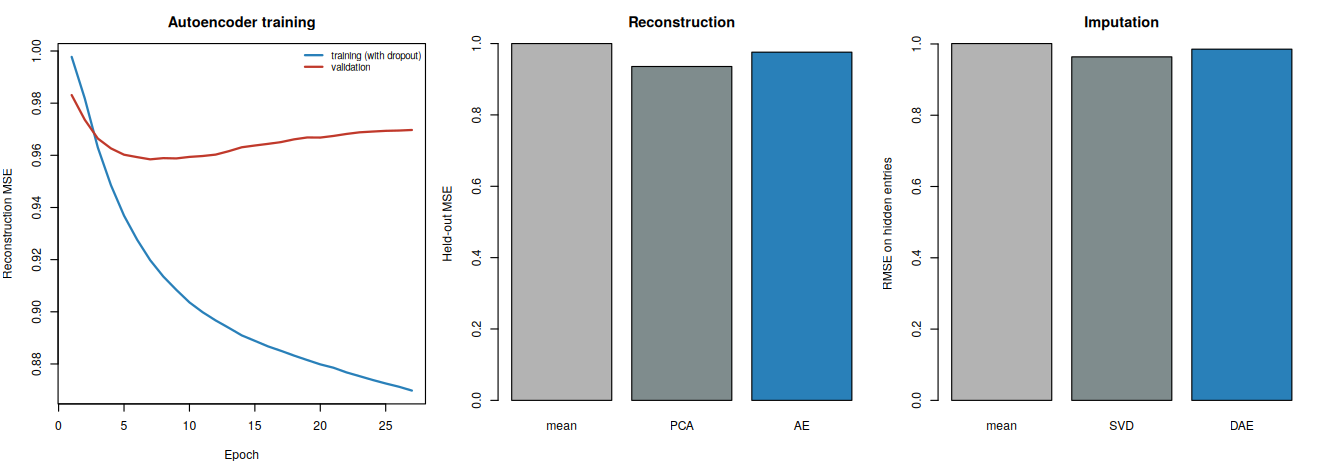

In [13]:
## imputation: hide 10% of the entries of the held-out children
set.seed(8); mask <- matrix(runif(length(Xte)) < 0.10, nrow(Xte)); Xmiss <- Xte; Xmiss[mask] <- 0          # 0 = feature mean after standardization
imp_ae <- mlp_predict(ae, Xmiss)
svd_impute <- function(Xtrain, Xmiss, mask, rank = 10, iters = 12) {
  M <- rbind(Xtrain, Xmiss); mk <- rbind(matrix(FALSE, nrow(Xtrain), ncol(Xtrain)), mask)
  for (i in seq_len(iters)) { s <- svd(M, nu = rank, nv = rank); Mh <- s$u %*% (s$d[1:rank] * t(s$v)); M[mk] <- Mh[mk] }
  M[(nrow(Xtrain) + 1):nrow(M), ]
}
imp_svd <- svd_impute(Xtr, Xmiss, mask)
rm <- function(imp) sqrt(mean((imp[mask] - Xte[mask])^2))
cat(sprintf("Imputation RMSE on %d hidden entries (standardized units)\n  feature mean: %.3f | iterative SVD (rank 10): %.3f | denoising autoencoder: %.3f\n", sum(mask), rm(Xmiss * 0), rm(imp_svd), rm(imp_ae)))
fig("p2_04_autoencoder", {
  par(mfrow = c(1, 3), mar = c(4, 4, 3, 1))
  plot(ae$hist$epoch, ae$hist$train, type = "l", lwd = 2, col = "#2980b9", ylim = range(c(ae$hist$train, ae$hist$val)), xlab = "Epoch", ylab = "Reconstruction MSE", main = "Autoencoder training")
  lines(ae$hist$epoch, ae$hist$val, lwd = 2, col = "#c0392b"); legend("topright", c("training (with dropout)", "validation"), col = c("#2980b9", "#c0392b"), lwd = 2, bty = "n", cex = 0.8)
  barplot(c(mean = 1, PCA = mean((Xte - rec_pca)^2), AE = mean((Xte - rec_ae)^2)), col = c("grey70", "#7f8c8d", "#2980b9"), ylab = "Held-out MSE", main = "Reconstruction")
  barplot(c(mean = rm(Xmiss * 0), SVD = rm(imp_svd), DAE = rm(imp_ae)), col = c("grey70", "#7f8c8d", "#2980b9"), ylab = "RMSE on hidden entries", main = "Imputation")
}, w = 12, h = 4.2)

### 7c. Sparse-input network (group-lasso on the first layer)

To make a network select features, a **group-lasso penalty** is applied to each feature's outgoing weights in the first layer (a proximal step that shrinks whole feature rows to exactly zero, in the spirit of LassoNet). Features whose rows survive are the selected ones. Training is noisy, so the number of surviving features does not fall smoothly as the penalty grows; the network with the best validation AUC is kept, and its features are ranked by weight norm and compared with the lasso and limma at a fixed budget of 60 features.

In [14]:
sp_grid <- c(2, 2.5, 3, 3.5, 4)
mu_a <- colMeans(Xc); sd_a <- apply(Xc, 2, sd); Xa <- sweep(sweep(Xc, 2, mu_a), 2, sd_a, "/")
set.seed(5); vi_a <- sample(N, 80)
sp <- lapply(sp_grid, function(pl) {
  f <- mlp_fit(Xa[-vi_a, ], y[-vi_a], c(P, 16, 1), loss_bce, epochs = 150, batch = 32, lr = 1e-3, wd = 1e-3, prox = pl, Xval = Xa[vi_a, ], yval = y[vi_a], patience = 30, seed = 2)
  rn <- sqrt(rowSums(f$P$W1^2)); list(f = f, sel = which(rn > 1e-8), rn = rn, auc = auc_rank(y[vi_a], as.numeric(mlp_predict(f, Xa[vi_a, ]))))
})
sp_tab <- do.call(rbind, lapply(seq_along(sp), function(i) data.frame(group_lasso_strength = sp_grid[i], n_selected = length(sp[[i]]$sel), TP = sum(is_true[sp[[i]]$sel]), FP = sum(!is_true[sp[[i]]$sel]),
                                                                      best_epoch = sp[[i]]$f$best_epoch, validation_AUC = round(sp[[i]]$auc, 3))))
print(sp_tab, row.names = FALSE)
best <- sp[[which.max(sapply(sp, function(z) z$auc))]]; k <- 60
top_sp <- order(best$rn, decreasing = TRUE)[1:k]
top_lasso <- order(abs(as.numeric(coef(cvfull, s = "lambda.min"))[-1]), decreasing = TRUE)[1:k]
top_limma <- order(abs(t_lim), decreasing = TRUE)[1:k]
cat("\nTop 60 features by each method (40 features are truly associated; random ranking would find 0.24)\n")
print(rbind("sparse-input network (weight norm)" = c(TP = sum(is_true[top_sp]), FP = sum(!is_true[top_sp])),
            "lasso (|coefficient|)" = c(TP = sum(is_true[top_lasso]), FP = sum(!is_true[top_lasso])),
            "limma + batch (|moderated t|)" = c(TP = sum(is_true[top_limma]), FP = sum(!is_true[top_limma]))))

 group_lasso_strength n_selected TP  FP best_epoch validation_AUC
                  2.0        611 36 575         12          0.753
                  2.5        447 30 417         27          0.756
                  3.0        320 31 289         56          0.797
                  3.5        157 26 131        150          0.825
                  4.0        489 18 471          2          0.647

Top 60 features by each method (40 features are truly associated; random ranking would find 0.24)
                                   TP FP
sparse-input network (weight norm) 23 37
lasso (|coefficient|)              28 32
limma + batch (|moderated t|)      32 28


### 7d. Attribution: which features does the network use?

**Integrated Gradients** assigns each input feature a share of the network's prediction by accumulating gradients along a path from a baseline (all-zero, the feature mean) to the actual input. It has a built-in check: attributions must add up to the difference between the prediction and the baseline prediction.

Attributions are only as meaningful as the model. Two networks are examined:

1. **Negative control:** the dense MLP on all 10,000 features, which cross-validation showed learns nothing. Its attributions should recover no true features.
2. **Screened network:** trained on the 100 features with the largest |t| (screening here uses all the labels, so this network is for illustrating attributions only, not for estimating performance). Its attributions are compared with the screening statistic and with lasso coefficients within the same 100 features.

Dense MLP on all features: true features among its top 40 by attribution = 0 (random ranking would find 0.16)

Completeness check: max |sum of attributions - (f(x) - f(baseline))| = 0.0106 
True features among the 100 screened: 35 

                  ranking_within_the_100 true_features_in_top_20
 Integrated Gradients (screened network)                      16
           |t| (the screening statistic)                      20
                     |lasso coefficient|                      18
               random ranking (expected)                       7


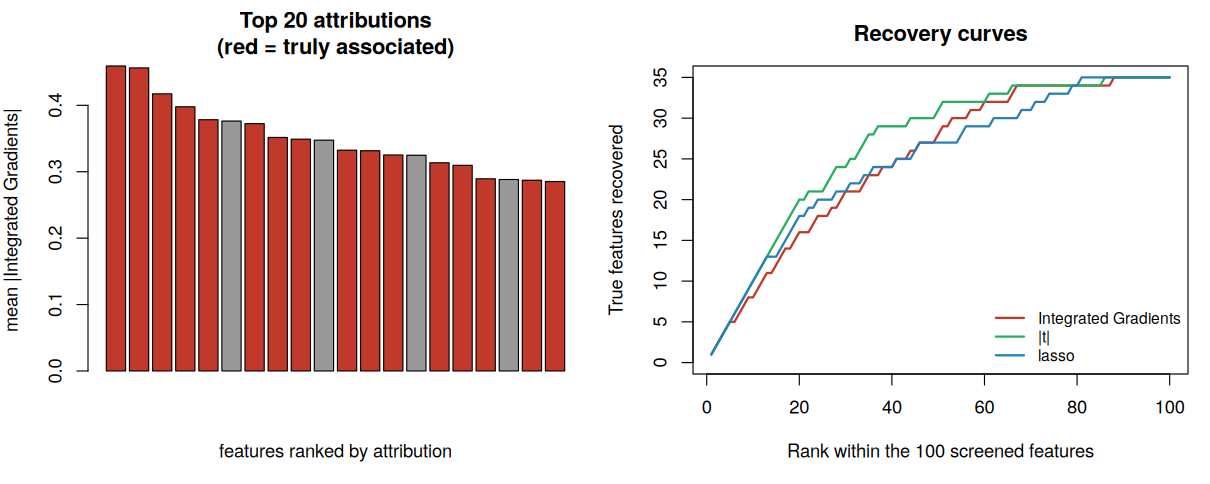

In [15]:
## 1. negative control: dense network on all features
fit_all <- mlp_fit(Xa[-vi_a, ], y[-vi_a], c(P, 32, 1), loss_bce, epochs = 80, batch = 32, lr = 1e-3, wd = 1e-2, drop_in = 0.5, drop_hid = 0.2,
                   Xval = Xa[vi_a, ], yval = y[vi_a], patience = 12, seed = 4)
imp_all <- colMeans(abs(integrated_gradients(fit_all, Xa, steps = 20)))
cat(sprintf("Dense MLP on all features: true features among its top 40 by attribution = %d (random ranking would find %.2f)\n\n", sum(is_true[order(imp_all, decreasing = TRUE)[1:40]]), 40 * S / P))
## 2. screened network
top100 <- order(abs(fast_t(Xa, y)$t), decreasing = TRUE)[1:100]
f_scr <- mlp_fit(Xa[-vi_a, top100], y[-vi_a], c(100, 16, 1), loss_bce, epochs = 80, batch = 32, lr = 1e-3, wd = 1e-2, drop_in = 0.1, drop_hid = 0.2,
                 Xval = Xa[vi_a, top100], yval = y[vi_a], patience = 12, seed = 4)
ig <- integrated_gradients(f_scr, Xa[, top100], steps = 200)
cat("Completeness check: max |sum of attributions - (f(x) - f(baseline))| =", signif(max(abs(rowSums(ig) - (mlp_predict(f_scr, Xa[, top100]) - mlp_predict(f_scr, Xa[, top100] * 0)))), 3), "\n")
cat("True features among the 100 screened:", sum(is_true[top100]), "\n\n")
imp <- colMeans(abs(ig)); cf100 <- abs(as.numeric(coef(cv.glmnet(Xa[, top100], y, family = "binomial", alpha = 1), s = "lambda.min"))[-1]); tt100 <- abs(fast_t(Xa, y)$t[top100])
kk <- 20; tk <- function(sc) sum(is_true[top100][order(sc, decreasing = TRUE)[1:kk]])
print(data.frame(ranking_within_the_100 = c("Integrated Gradients (screened network)", "|t| (the screening statistic)", "|lasso coefficient|", "random ranking (expected)"),
                 true_features_in_top_20 = c(tk(imp), tk(tt100), tk(cf100), round(kk * sum(is_true[top100]) / 100, 1))), row.names = FALSE)
fig("p2_05_attribution", {
  par(mfrow = c(1, 2), mar = c(5, 4, 3, 1))
  o <- order(imp, decreasing = TRUE)[1:20]
  barplot(imp[o], col = ifelse(is_true[top100][o], "#c0392b", "grey60"), names.arg = NA, ylab = "mean |Integrated Gradients|", main = "Top 20 attributions\n(red = truly associated)", xlab = "features ranked by attribution")
  plot(NA, xlim = c(1, 100), ylim = c(0, sum(is_true[top100])), xlab = "Rank within the 100 screened features", ylab = "True features recovered", main = "Recovery curves")
  for (i in 1:3) { sc <- list(imp, tt100, cf100)[[i]]; oo <- order(sc, decreasing = TRUE); lines(1:100, cumsum(is_true[top100][oo]), lwd = 2, col = c("#c0392b", "#27ae60", "#2980b9")[i]) }
  legend("bottomright", c("Integrated Gradients", "|t|", "lasso"), col = c("#c0392b", "#27ae60", "#2980b9"), lwd = 2, bty = "n", cex = 0.85)
}, w = 11, h = 4.4)

## 8. Summary and honest reading of the results

- **Batch effects matter.** Because batch is confounded with the outcome, ignoring it produces many spurious discoveries, and random-split validation overstates how well a model will work on a new batch. Batch correction and leave-one-batch-out validation are the honest choices.
- **Multiplicity.** Uncorrected p-values on 10,000 features are unusable; BH and moderated tests with batch adjustment give interpretable findings, and the simulation shows the same on pure noise.
- **Prediction and selection.** Penalized regression with nested cross-validation gives modest but real predictive ability; the permutation test supports that it is above chance. Stability selection and sample splitting separate reliable features from artifacts of selection.
- **Ridge.** Ridge regression keeps every feature and, with 10,000 features of which 40 matter, cannot isolate the sparse signal; its cross-validated AUC stays near 0.5, while the lasso and elastic net, which select features, reach about 0.85 to 0.87.\n- **Neural networks.** On identical folds, a dense network given all 10,000 features learns nothing (AUC near 0.5), and its attributions are correspondingly meaningless; with in-fold screening to 100 features it becomes competitive but does not beat the elastic net. The denoising autoencoder reconstructs better than the feature mean but not better than PCA, and imputes only slightly better than the mean, behind low-rank SVD; unsupervised compression keeps little of the outcome signal. The sparse-input network recovers most true features but also keeps many false ones. With 400 samples, 10,000 features and a mostly sparse linear signal, classical methods are as good or better and far easier to validate and explain. Networks become more attractive with thousands of samples and strongly nonlinear structure.
- **Limitations.** Synthetic data with a built-in linear signal; one simulated data set for the main comparisons (the simulation study covers the failure modes with repetitions); networks use fixed, lightly tuned hyperparameters; batch-adversarial and multi-omics networks are left for Part 3.